## 0. Importing libraries

In [34]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, precision_score, roc_auc_score, recall_score, f1_score, roc_curve, auc
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import copy
from pathlib import Path
import pandas as pd
import kagglehub

## 1. Loading dataset

In [35]:
BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "dataset"

try:
    path = kagglehub.dataset_download("janiobachmann/bank-marketing-dataset")
    csv_files = list(Path(path).glob("*.csv"))
    if not csv_files:
        raise FileNotFoundError("No CSV file found in Kaggle dataset.")
    df = pd.read_csv(csv_files[0])
except Exception as e:
    print("Kaggle download failed:", e)
    print("Loading local dataset instead.")

    df = pd.read_csv(DATA_DIR / "bank.csv")

df.head()

Kaggle download failed: 403 Client Error.

You don't have permission to access resource at URL: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDataset. Please make sure you are authenticated if you are trying to access a private resource or a resource requiring consent.
Loading local dataset instead.


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


Dataset columns:

In [36]:
print('Columns:', df.columns.tolist())

Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'deposit']


In [37]:
df.describe(include='all')

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
count,11162.000000,11162,11162,11162,11162,11162.000000,11162,11162,11162,11162.000000,11162,11162.000000,11162.000000,11162.000000,11162.000000,11162,11162
unique,NaN,12,3,4,2,NaN,2,2,3,NaN,12,NaN,NaN,NaN,NaN,4,2
top,NaN,management,married,secondary,no,NaN,no,no,cellular,NaN,may,NaN,NaN,NaN,NaN,unknown,no
freq,NaN,2566,6351,5476,10994,NaN,5881,9702,8042,NaN,2824,NaN,NaN,NaN,NaN,8326,5873
mean,41.231948,NaN,NaN,NaN,NaN,1528.538524,NaN,NaN,NaN,15.658036,NaN,371.993818,2.508421,51.330407,0.832557,NaN,NaN
std,11.913369,NaN,NaN,NaN,NaN,3225.413326,NaN,NaN,NaN,8.420740,NaN,347.128386,2.722077,108.758282,2.292007,NaN,NaN
min,18.000000,NaN,NaN,NaN,NaN,-6847.000000,NaN,NaN,NaN,1.000000,NaN,2.000000,1.000000,-1.000000,0.000000,NaN,NaN
25%,32.000000,NaN,NaN,NaN,NaN,122.000000,NaN,NaN,NaN,8.000000,NaN,138.000000,1.000000,-1.000000,0.000000,NaN,NaN
50%,39.000000,NaN,NaN,NaN,NaN,550.000000,NaN,NaN,NaN,15.000000,NaN,255.000000,2.000000,-1.000000,0.000000,NaN,NaN
75%,49.000000,NaN,NaN,NaN,NaN,1708.000000,NaN,NaN,NaN,22.000000,NaN,496.000000,3.000000,20.750000,1.000000,NaN,NaN


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB


Target destribution:

In [39]:
print('Distribution of target:')
df['deposit'].value_counts()

Distribution of target:


deposit
no     5873
yes    5289
Name: count, dtype: int64

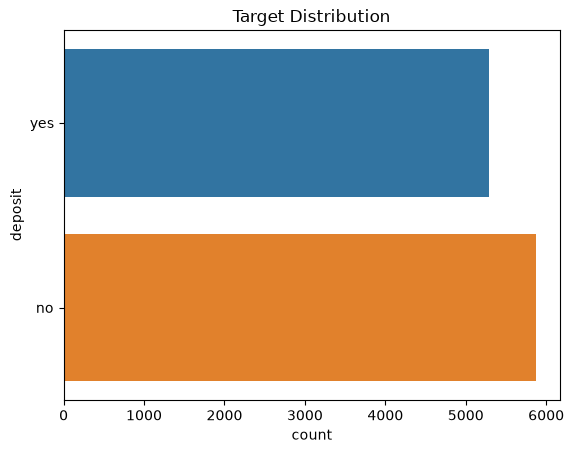

In [40]:
sns.countplot(data=df, y='deposit', hue='deposit')
plt.title('Target Distribution')
plt.show()

## 2. Data preprocessing

Misssing values:

In [41]:
print('Missing values:')
print(df.isna().sum())

Missing values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64


In [42]:
print("Data types:")
print(df.dtypes.value_counts())

Data types:
str      10
int64     7
Name: count, dtype: int64


Numerical columns:

In [43]:
numerical_columns = df.select_dtypes(include='number').columns.tolist()
print(f'numerical_columns: {numerical_columns}')

numerical_columns: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


In [44]:
for col in numerical_columns:
    print(f'Column: {col} has {df[col].nunique()} unique values.')
    print(f'Min: {df[col].min()}')
    print(f'Max: {df[col].max()}')

Column: age has 76 unique values.
Min: 18
Max: 95
Column: balance has 3805 unique values.
Min: -6847
Max: 81204
Column: day has 31 unique values.
Min: 1
Max: 31
Column: duration has 1428 unique values.
Min: 2
Max: 3881
Column: campaign has 36 unique values.
Min: 1
Max: 63
Column: pdays has 472 unique values.
Min: -1
Max: 854
Column: previous has 34 unique values.
Min: 0
Max: 58


Categorical columns:

In [45]:
categorical_columns = df.select_dtypes(include=['str', 'object', 'category']).columns.tolist()
print(f'categorical_columns: {categorical_columns}')

categorical_columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']


In [46]:
df[categorical_columns].head()

,job,marital,education,default,housing,loan,contact,month,poutcome,deposit
0,admin.,married,secondary,no,yes,no,unknown,may,unknown,yes
1,admin.,married,secondary,no,no,no,unknown,may,unknown,yes
2,technician,married,secondary,no,yes,no,unknown,may,unknown,yes
3,services,married,secondary,no,yes,no,unknown,may,unknown,yes
4,admin.,married,tertiary,no,no,no,unknown,may,unknown,yes


In [47]:
print(f'Target unique values: {df["deposit"].unique()}')

Target unique values: <StringArray>
['yes', 'no']
Length: 2, dtype: str


Separate features and target:

In [48]:
target_column = 'deposit'
x = df.drop(columns=['deposit']).copy()
y = df[target_column].map({'yes': 1, 'no': 0})


Validate target encoding:

In [49]:
assert y.notna().all(), "Unexpected target values!"
y = y.astype(np.float32)

One-hot encoding:

In [50]:
x = pd.get_dummies(x, drop_first=True, dtype=np.float32)

Feature columns:

In [51]:
feature_columns = x.columns.tolist()
x = x.astype(np.float32)
print('Number of features:', len(feature_columns))
print('Feature columns:', feature_columns)

print('x Shape:', x.shape)
print('y Shape:', y.shape)

display(x.head())

Number of features: 42
Feature columns: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'job_unknown', 'marital_married', 'marital_single', 'education_secondary', 'education_tertiary', 'education_unknown', 'default_yes', 'housing_yes', 'loan_yes', 'contact_telephone', 'contact_unknown', 'month_aug', 'month_dec', 'month_feb', 'month_jan', 'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct', 'month_sep', 'poutcome_other', 'poutcome_success', 'poutcome_unknown']
x Shape: (11162, 42)
y Shape: (11162,)


,age,balance,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,59.0,2343.0,5.0,1042.0,1.0,-1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,56.0,45.0,5.0,1467.0,1.0,-1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,41.0,1270.0,5.0,1389.0,1.0,-1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,55.0,2476.0,5.0,579.0,1.0,-1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,54.0,184.0,5.0,673.0,2.0,-1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


Train-test split:

In [52]:
x_train, x_temp, y_train, y_temp = train_test_split(x, y, train_size= 0.6, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, train_size= 0.5, random_state=42, stratify=y_temp)

print('Train:', x_train.shape, y_train.shape)
print('Validation:', x_val.shape, y_val.shape)
print('Test:', x_test.shape, y_test.shape)

Train: (6697, 42) (6697,)
Validation: (2232, 42) (2232,)
Test: (2233, 42) (2233,)


Feature scaling:

In [53]:
scaler = MinMaxScaler()

In [54]:
x_train[numerical_columns] = scaler.fit_transform(x_train[numerical_columns])
x_val[numerical_columns] = scaler.transform(x_val[numerical_columns])
x_test[numerical_columns] = scaler.transform(x_test[numerical_columns])

Convert features to Pytorch tensors:

In [55]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.manual_seed(42)
x_train = torch.tensor(x_train.values, device= device, dtype= torch.float32)
x_val = torch.tensor(x_val.values, device= device, dtype= torch.float32)
x_test = torch.tensor(x_test.values, device= device, dtype= torch.float32)

y_train = torch.tensor(y_train.values, device= device, dtype= torch.float32).reshape(-1, 1)
y_val = torch.tensor(y_val.values, device= device, dtype= torch.float32).reshape(-1, 1)
y_test = torch.tensor(y_test.values, device= device, dtype= torch.float32).reshape(-1, 1)

In [56]:
print("x_train.shape:", x_train.shape)
print("x_val.shape:", x_val.shape)
print("x_test.shape:", x_test.shape)

print()

print("y_train.shape:", y_train.shape)
print("y_val.shape:", y_val.shape)
print("y_test.shape:", y_test.shape)

x_train.shape: torch.Size([6697, 42])
x_val.shape: torch.Size([2232, 42])
x_test.shape: torch.Size([2233, 42])

y_train.shape: torch.Size([6697, 1])
y_val.shape: torch.Size([2232, 1])
y_test.shape: torch.Size([2233, 1])


## 3. Build the model

In [57]:
class NeuralNetwork(nn.Module):
    def __init__(self, input_dim= x_train.shape[1], output_dim= 1, dropout_rate=0.1):
        super().__init__()
        
        self.fc1 = nn.Linear(input_dim, 52)
        self.fc2 = nn.Linear(52, 94)
        self.fc3 = nn.Linear(94, 256)
        self.out = nn.Linear(256, output_dim)

        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()
        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, x):
        
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc2(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.fc3(x)
        x = self.relu(x)
        x = self.dropout(x)

        x = self.out(x)
        x = self.sigmoid(x)

        return x

## 4. Training function

In [58]:
def train_network(model, optimizer, criterion, epochs, batch_size, x_train, y_train, x_val, y_val, lambda_L1= 0, patience= 30):
    data_length = x_train.shape[0]
    train_loss_list = []
    val_loss_list = []
    best_val_loss = float('inf')
    best_epoch = 0
    best_model_state = None
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        num_batches = 0
        permutation = torch.randperm(data_length)
        
        for i in range(0, data_length, batch_size):
            indices = permutation[i: i + batch_size]
            input_data = x_train[indices]
            labels = y_train[indices]

            output_data = model(input_data)
            loss = criterion(output_data, labels)
            batch_loss = loss.item()

            if lambda_L1 > 0:
                L1_loss = 0
                for name, p in model.named_parameters():
                    if 'weight' in name:
                        L1_loss += p.abs().sum()
                loss = loss + lambda_L1 * L1_loss

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            train_loss += batch_loss
            num_batches += 1
        epoch_train_loss = train_loss / num_batches
        train_loss_list.append(epoch_train_loss)

        model.eval()
        with torch.inference_mode():
            val_predictions = model(x_val)
            epoch_val_loss = criterion(val_predictions, y_val).item()
            val_loss_list.append(epoch_val_loss)
        
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
        
        if epoch + 1 - best_epoch >= patience:
            print(f"Early stopping at epoch {epoch + 1}")
            break

        if (epoch + 1) % 25 == 0:
            print(
                f"Epoch: {epoch + 1} | "
                f"Train Loss: {epoch_train_loss:.4f} | "
                f"Val Loss: {epoch_val_loss:.4f}"
            )

    # Restore best model
    model.load_state_dict(best_model_state)

    print("\nTraining completed!")
    print("Best Epoch:", best_epoch)
    print("Best Validation Loss:", round(best_val_loss, 4))

    return {
        "train_loss": train_loss_list,
        "val_loss": val_loss_list,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss
    }

## 5. Evaluation function

In [59]:
def evaluate_model(model, x_train, y_train, x_val, y_val, x_test, y_test, criterion, history, threshold=0.5):
    model.eval()
    with torch.inference_mode():
        train_prob = model(x_train).cpu().numpy()
        val_prob = model(x_val).cpu().numpy()
        test_prob = model(x_test).cpu().numpy()
    
    train_pred = (train_prob >= threshold).astype(int)
    val_pred = (val_prob >= threshold).astype(int)
    test_pred = (test_prob >= threshold).astype(int)

    Dataset = [
        ('Training', y_train, train_prob, train_pred),
        ('Validation', y_val, val_prob, val_pred),
        ('Test', y_test, test_prob, test_pred)
    ]
    
    # Metrics
    for name, y_true, y_prob, y_pred in Dataset:
        y_true = y_true.cpu().numpy()
        print(f"\n{'=' * 15} {name} {'=' * 15}")
        current_loss = criterion(
            torch.tensor(y_prob, dtype= torch.float32),
            torch.tensor(y_true, dtype= torch.float32)
        ).item()
        
        print("Loss:", round(current_loss, 4))
        print("Accuracy:", round(accuracy_score(y_true, y_pred), 3))
        print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 3))
        print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 3))
        print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 3))
        print("ROC-AUC:", round(roc_auc_score(y_true, y_prob), 3))
    
    # Loss curves
    plt.figure(figsize=(10, 5))
    plt.plot(history['train_loss'], label='Training loss')
    plt.plot(history['val_loss'], label='Validation loss')
    plt.title("Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()
    plt.show()

   # ROC curve
    plt.figure(figsize=(8, 6))
    for name, y_true, y_prob, y_pred in Dataset:
        y_true = y_true.cpu().numpy()
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        roc_auc_value = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'{name} AUC = {roc_auc_value:.3f}')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.title("ROC Curves")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.grid()
    plt.show()
    
    # Test confusion matrix
    cm = confusion_matrix(y_test.cpu().numpy(), test_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title("Test Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    # Test classification report
    print("\nTest Classification Report:")
    print(classification_report( y_test.cpu().numpy(), test_pred, zero_division=0))

## 6. Hyperparameters and baseline model

Hyperparameters:

In [60]:
epochs = 500
batch_size = 128
lr = 0.001
weight_decay = 0.0
lambda_L1 = 0.0
dropout_rate = 0.1
patience = 30

In [61]:
criterion = nn.BCELoss()

Initialize model:

In [62]:
model = NeuralNetwork(
    input_dim=x_train.shape[1],
    output_dim=y_train.shape[1],
    dropout_rate=dropout_rate
).to(device)

In [63]:
optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

Training:

In [64]:
history = train_network(
    model,
    optimizer,
    criterion,
    epochs,
    batch_size,
    x_train,
    y_train,
    x_val,
    y_val,
    lambda_L1,
    patience
)

Epoch: 25 | Train Loss: 0.3121 | Val Loss: 0.3605
Early stopping at epoch 49

Training completed!
Best Epoch: 19
Best Validation Loss: 0.3513


## 7. Regularization Experiments

In [65]:
experiments = [
    {
        "name": "Baseline",
        "lambda_L1": 0.0,
        "weight_decay": 0.0,
        "dropout": 0.1
    },
    {
        "name": "L1 Regularization",
        "lambda_L1": 1e-5,
        "weight_decay": 0.0,
        "dropout": 0.1
    },
    {
        "name": "L2 Regularization",
        "lambda_L1": 0.0,
        "weight_decay": 1e-5,
        "dropout": 0.1
    },
    {
        "name": "Dropout",
        "lambda_L1": 0.0,
        "weight_decay": 0.0,
        "dropout": 0.3
    },
    {
        "name": "L1 + L2 + Dropout",
        "lambda_L1": 1e-5,
        "weight_decay": 1e-5,
        "dropout": 0.3
    }
]

results = []

for config in experiments:

    print("\n" + "=" * 50)
    print("Experiment:", config["name"])
    print("=" * 50)

    torch.manual_seed(42)

    model = NeuralNetwork(
        input_dim=x_train.shape[1],
        output_dim=y_train.shape[1],
        dropout_rate=config["dropout"]
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=config["weight_decay"]
    )

    history = train_network(
        model,
        optimizer,
        criterion,
        epochs,
        batch_size,
        x_train,
        y_train,
        x_val,
        y_val,
        config["lambda_L1"],
        patience
    )

    # Validation evaluation
    model.eval()

    with torch.inference_mode():

        val_prob = model(x_val).cpu().numpy()

    val_pred = (val_prob >= 0.5).astype(int)

    val_true = y_val.cpu().numpy()

    results.append({
        "Experiment": config["name"],
        "Best Epoch": history["best_epoch"],
        "Best Val Loss": history["best_val_loss"],
        "Val Accuracy": accuracy_score(val_true, val_pred),
        "Val Precision": precision_score(
            val_true, val_pred, zero_division=0
        ),
        "Val Recall": recall_score(
            val_true, val_pred, zero_division=0
        ),
        "Val F1": f1_score(
            val_true, val_pred, zero_division=0
        ),
        "Val ROC-AUC": roc_auc_score(val_true, val_prob)
    })

# Results table
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="Val F1",
        ascending=False
    ).reset_index(drop=True)
)



Experiment: Baseline
Epoch: 25 | Train Loss: 0.3121 | Val Loss: 0.3605
Early stopping at epoch 49

Training completed!
Best Epoch: 19
Best Validation Loss: 0.3513

Experiment: L1 Regularization
Epoch: 25 | Train Loss: 0.3217 | Val Loss: 0.3536
Early stopping at epoch 48

Training completed!
Best Epoch: 18
Best Validation Loss: 0.3477

Experiment: L2 Regularization
Epoch: 25 | Train Loss: 0.3130 | Val Loss: 0.3607
Early stopping at epoch 46

Training completed!
Best Epoch: 16
Best Validation Loss: 0.3524

Experiment: Dropout
Epoch: 25 | Train Loss: 0.3387 | Val Loss: 0.3496
Epoch: 50 | Train Loss: 0.3037 | Val Loss: 0.3589
Early stopping at epoch 51

Training completed!
Best Epoch: 21
Best Validation Loss: 0.3415

Experiment: L1 + L2 + Dropout
Epoch: 25 | Train Loss: 0.3364 | Val Loss: 0.3446
Early stopping at epoch 49

Training completed!
Best Epoch: 19
Best Validation Loss: 0.3397


,Experiment,Best Epoch,Best Val Loss,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC
0,Dropout,21,0.341495,0.857079,0.815004,0.903592,0.857015,0.921589
1,L1 + L2 + Dropout,19,0.339683,0.855287,0.815993,0.896975,0.854570,0.922778
2,L1 Regularization,18,0.347694,0.853943,0.809645,0.904537,0.854464,0.919063
3,Baseline,19,0.351286,0.853943,0.810696,0.902647,0.854204,0.917155
4,L2 Regularization,16,0.352366,0.851703,0.808312,0.900756,0.852034,0.917722


## 8. Final Model Selection and Test Evaluation

Best Experiment: Dropout
Best Configuration: {'name': 'Dropout', 'lambda_L1': 0.0, 'weight_decay': 0.0, 'dropout': 0.3}
Epoch: 25 | Train Loss: 0.3387 | Val Loss: 0.3496
Epoch: 50 | Train Loss: 0.3037 | Val Loss: 0.3589
Early stopping at epoch 51

Training completed!
Best Epoch: 21
Best Validation Loss: 0.3415

=============== Training ===============
Loss: 0.3099
Accuracy: 0.873
Precision: 0.831
Recall: 0.918
F1-score: 0.872
ROC-AUC: 0.935

=============== Validation ===============
Loss: 0.3415
Accuracy: 0.857
Precision: 0.815
Recall: 0.904
F1-score: 0.857
ROC-AUC: 0.922

=============== Test ===============
Loss: 0.3616
Accuracy: 0.847
Precision: 0.811
Recall: 0.882
F1-score: 0.845
ROC-AUC: 0.915


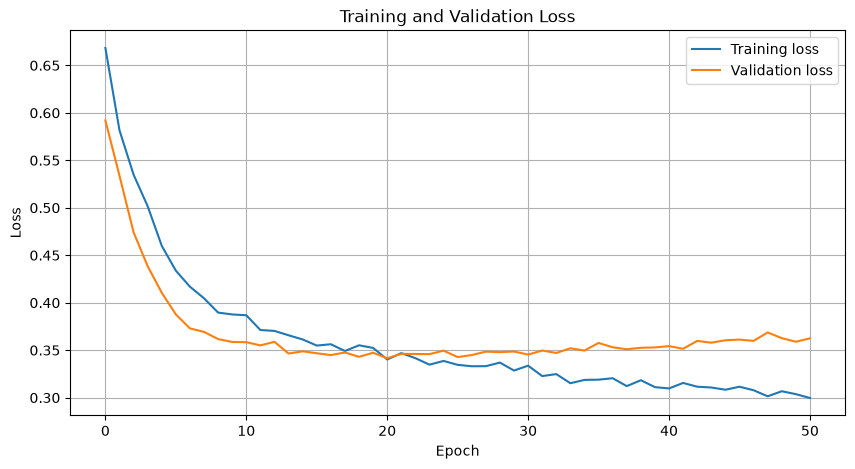

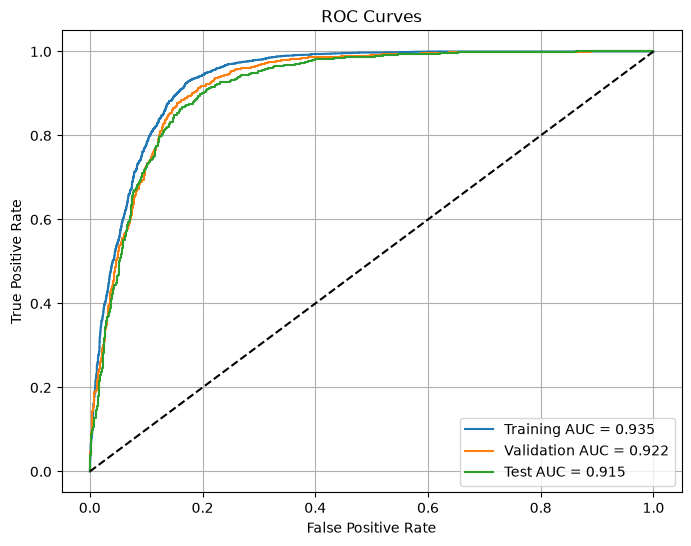

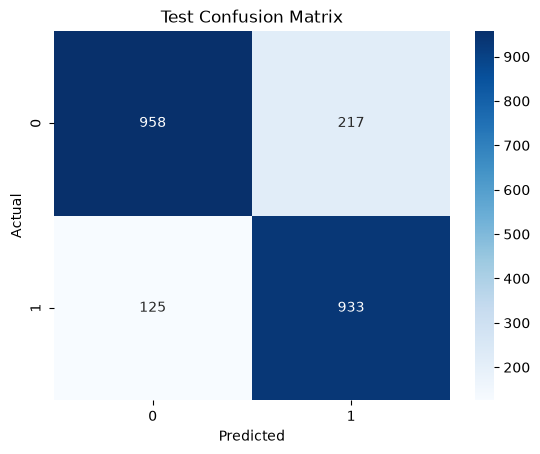


Test Classification Report:
              precision    recall  f1-score   support

         0.0       0.88      0.82      0.85      1175
         1.0       0.81      0.88      0.85      1058

    accuracy                           0.85      2233
   macro avg       0.85      0.85      0.85      2233
weighted avg       0.85      0.85      0.85      2233



In [66]:
best_experiment_name = results_df.loc[
    results_df["Val F1"].idxmax(),
    "Experiment"
]

best_config = next(
    config for config in experiments
    if config["name"] == best_experiment_name
)

print("Best Experiment:", best_experiment_name)
print("Best Configuration:", best_config)

# Initialize final model
torch.manual_seed(42)

final_model = NeuralNetwork(
    input_dim=x_train.shape[1],
    output_dim=y_train.shape[1],
    dropout_rate=best_config["dropout"]
).to(device)

# Final optimizer
final_optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=lr,
    weight_decay=best_config["weight_decay"]
)

# Train final model
final_history = train_network(
    final_model,
    final_optimizer,
    criterion,
    epochs,
    batch_size,
    x_train,
    y_train,
    x_val,
    y_val,
    best_config["lambda_L1"],
    patience
)

# Final evaluation
evaluate_model(
    final_model,
    x_train,
    y_train,
    x_val,
    y_val,
    x_test,
    y_test,
    criterion,
    final_history 
)